# Лабораторна 5. Донавчання BERT для визначення спаму в SMS


## 0. Відповіді на контрольні запитання

Відповіді охоплюють запитання 1–30 з лабораторної. Коментарі до демо спираються на код і збережені виходи наданих ноутбуків. Для пунктів 9–10 додатково виконано локальний запуск BERT на MRPC протягом шести епох і перевірено чотири власні пари. Нижче, після відповідей, наведено окремий проєкт визначення SMS-спаму.




#### 1. Як довго виконувалися клітинки ноутбуку `01_bert_head`? Чи були проблеми з запуском, які?

У збереженому виводі `01_bert_head` навчання протягом трьох епох на Tesla T4 тривало приблизно 1 хв 1 с. Це час тренувального циклу, без повного завантаження бібліотек, даних і моделі. Повний час усіх клітинок окремо не зафіксований. Критичних помилок у збережених виходах немає; попередження про нову голову очікуване, бо її ваги створюються заново. Час додаткового локального запуску на шість епох наведено в пункті 9.

#### 2. Як Ви розумієте, що таке токен `[CLS]`? Яким чином він виконує свою функцію?

`[CLS]` — спеціальний токен на початку входу BERT. Завдяки механізму self-attention його представлення залежить від інших токенів послідовності. Для класифікації модель бере це контекстне представлення, у стандартному BERT додатково обробляє його pooler-шаром і передає в класифікаційну голову. Сам токен не містить готового змісту речення: корисне представлення формується навченими шарами.

#### 3. Яке пряме застосування базової моделі bert-base-uncased?

Без додавання нової голови `bert-base-uncased` можна застосувати до заповнення пропусків `[MASK]`: модель прогнозує ймовірні токени з урахуванням контексту ліворуч і праворуч. Це й показує `pipeline('fill-mask')` у демо. Для задачі спаму чи визначення парафраз потрібна окрема навчена класифікаційна голова.

#### 4. Як Ви вважаєте, чи варто боротися (і якщо так, то яким чином) з проявами сексизму LLM-моделей?

Так, особливо якщо рішення моделі впливають на людей. Навчальні тексти можуть містити стереотипи, і модель відтворює їх як статистичні закономірності. Варто перевіряти відповіді на збалансованих прикладах, покращувати розмітку й склад даних та проводити додаткове навчання на коректних прикладах. Оцінювати потрібно конкретну поведінку моделі, щоб зменшення упередженості не зводилося лише до приховування окремих слів.

#### 5. Для чого в секції "Токенізація пари речень" виводяться числа 0 і 1?

Це `token_type_ids`: значення 0 позначає токени першого сегмента, значення 1 — другого. Для пари речень модель так розрізняє їхню належність. Це не оцінки якості й не мітки класів. `[CLS]` і перший `[SEP]` належать до першого сегмента, другий `[SEP]` — до другого.

#### 6. Що позначають числа 768 і 2, що виводяться після завантаження `AutoModelForSequenceClassification.from_pretrained()`?

У `Linear(in_features=768, out_features=2)` число 768 — розмір прихованого представлення BERT-base, що надходить у голову. Число 2 — кількість вихідних класів: парафраз і не парафраз. Голова перетворює вектор із 768 значень на два logits, які можна перетворити на ймовірності через softmax.

#### 7. Те що в кістяку (backbone) набагато більше параметрів ніж в голові, це добре чи погано в нашому випадку?

Це природно для передавального навчання: backbone уже містить вивчені мовні закономірності, а невелика голова лише перетворює представлення на потрібні класи. У демо backbone має 109 482 240 параметрів, голова — 1538. Перевага — використання попереднього навчання; недолік повного донавчання — витрати пам’яті й ризик перенавчання, бо оновлюється весь backbone.

#### 8. Що саме вимірюється за допомогою метрик accuracy & F1 в `01_bert_head`?

У MRPC accuracy — частка пар речень, для яких правильно визначено, чи є вони парафразами. F1 об’єднує precision і recall для позитивного класу `equivalent`. Вони оцінюють класифікацію пар на валідаційному наборі, а не якість генерації тексту. У збереженому демо після трьох епох accuracy = 0.8603, F1 = 0.9016.

#### 9. Збільшіть кількість епох тренування в `01_bert_head`, покажіть (скопіювавши результати) що відбувається і чому.

Кількість епох збільшено з 3 до 6 в окремому локальному експерименті на MRPC. Learning rate залишено 2e-5, batch size — 16, seed — 42; тренуються всі ваги BERT. Нижче наведені вимірювання одного шестиепохового запуску. Показник для третьої епохи всередині нього не є побітовим відтворенням початкового демо: довший бюджет змінює розклад learning rate.

| Епоха | Validation loss | Accuracy | F1 |
| --- | --- | --- | --- |
| 1 | 0.3789 | 0.8505 | 0.8950 |
| 2 | 0.4408 | 0.8309 | 0.8871 |
| 3 | 0.5018 | 0.8480 | 0.8839 |
| 4 | 0.6072 | 0.8505 | 0.8928 |
| 5 | 0.6957 | 0.8554 | 0.8977 |
| 6 | 0.7026 | 0.8603 | 0.9009 |

Шість епох тривали 47.4 с на NVIDIA GeForce RTX 5070. Між третьою й шостою епохами F1 змінився з 0.8839 до 0.9009, але validation loss зріс з 0.5018 до 0.7026. Найменша втрата у цьому запуску була після першої епохи: 0.3789. Отже, більше епох не гарантує кращого узагальнення. Cross-entropy враховує впевненість прогнозів, тоді як accuracy і F1 залежать від вибраних класів: модель може стати впевненішою у своїх помилках, тому loss зростає навіть при невеликому покращенні F1. Для практичного навчання доцільно зберігати найкращий checkpoint за validation loss і застосовувати early stopping.

#### 10. Додайте ще 4 перевірки на власних даних в пункті 4 в `01_bert_head`.

Після шестиепохового донавчання BERT на MRPC перевірено ще чотири власні пари. Мітка 1 означає парафраз, 0 — різний зміст. Вони не додавалися до навчального набору.

| Речення 1 | Речення 2 | Правильна мітка | Прогноз | P(парафраз) |
| --- | --- | --- | --- | --- |
| The lecture starts at nine. | The class begins at 9 a.m. | 1 | 1 | 0.9946 |
| He sold his old bike. | He bought a new bicycle. | 0 | 1 | 0.9987 |
| The meeting was cancelled. | The meeting will not take place. | 1 | 1 | 0.9958 |
| The shop opens on Sunday. | The shop is closed on Sunday. | 0 | 1 | 0.9976 |

Це окремі демонстраційні приклади, а не заміна метрик на всій валідаційній вибірці.

Правильно класифіковано 2 з 4 пар. У другій парі модель не розрізнила продаж і купівлю, у четвертій — відкритий і закритий магазин. Висока схожість слів не означає однаковий зміст; ці приклади показують, що модель може помилятися на протилежних твердженнях навіть із високою впевненістю.



#### 11. Як довго виконувалися клітинки ноутбуку `02_chat_templates`? Чи були проблеми з запуском, які?

Повний час виконання `02_chat_templates` у наданому файлі не зафіксований, тому точне число вказати неможливо. Найбільше часу потребують завантаження двох моделей SmolLM3-3B і генерація відповідей. У збережених виходах немає критичного збою; є попередження про запити без HF_TOKEN, обробку пробілів BPE-токенізатором і конфігурацію RoPE. Токен доступу не є обов’язковим для цих публічних моделей.

#### 12. Для чого змінювати параметр `add_generation_prompt` в методі `apply_chat_template()` при використанні моделі? Як по згенерованим розмовам можна дізнатися значення цього параметру, яке було задано при виклику метода?

`add_generation_prompt=True` додає наприкінці відформатованого входу початок повідомлення асистента, щоб модель продовжила саме його. `False` не додає цей заголовок і підходить для вже завершених навчальних діалогів. У показаному шаблоні різницю видно за кінцевим `<|im_start|>assistant`. За самою відповіддю без початкового відформатованого промпту надійно встановити значення параметра не завжди можна.

#### 13. Чим відрізняються ролі `system` від `assistant` в шаблонах розмов?

`system` містить загальні інструкції для поведінки моделі: роль, обмеження, формат відповіді. `assistant` позначає попередню або еталонну відповідь самої моделі. Під час SFT саме повідомлення асистента зазвичай є цільовим текстом, який модель має навчитися відтворювати.

#### 14. Прокоментуйте вивід даних в секції 2 «Як шаблон розмови форматує діалог». Які секції було додано шаблонізатором розмов і для чого?

Шаблон SmolLM3 додає межі повідомлень `<|im_start|>` і `<|im_end|>`, назви ролей та службовий system-блок. У ньому є секції `Metadata` з датами й режимом міркувань та `Custom Instructions` з інструкціями. Для `/think` додаються правила оформлення міркувань і відповіді. За `add_generation_prompt=True` наприкінці з’являється заголовок асистента. Це узгоджує діалог із форматом, на якому навчалася модель.

#### 15. Прокоментуйте різницю між Base і Instruct, проглянувши вивід в секції 3.

У збереженому прикладі Base починає з продовження «How does it work?», а потім переходить до пояснення квантових обчислень. Instruct одразу відповідає на запит і структурує пояснення як перелік. Base передбачає продовження тексту, а Instruct додатково навчена відповідати на інструкції в діалозі. Обидві відповіді обмежені бюджетом генерації, тому їхня обірваність не доводить відсутності потрібних знань.

#### 16. Чому в режимі `/think` при генерації було передано параметр `max_new_tokens=300`?

Бюджет у 300 нових токенів дає більше місця для проміжних міркувань і фінальної відповіді. У наданому коді `max_new_tokens=300` передається для обох режимів, а не лише для `/think`. Навіть цього бюджету для `/think` іноді не вистачає: модель витрачає токени на міркування, і відповідь обривається до завершення.

#### 17. Чи впоралася модель з математичними задачами? Який би режим генерації Ви обрали для себе, якщо б Вам потрібна була допомога?

У `/no_think` модель дала правильні результати всіх трьох задач: 360, 5 чашок борошна та 18.95 долара. У `/think` у міркуваннях теж є правильні обчислення, але збережені відповіді обриваються через ліміт токенів і не завжди містять завершений підсумок. Для цих простих задач я обрав би `/no_think`, а для складніших перевірив би `/think` з більшим бюджетом і незалежною перевіркою результату.

#### 18. Які відмінності в шаблонах розмов Ви помітили в секції 5?

SmolLM3 і Qwen3 використовують маркери `<|im_start|>` та `<|im_end|>`, але SmolLM3 додає власні метадані й інструкції режиму міркувань. У Qwen3 видно блоки `<think>...</think>`; при `enable_thinking=False` шаблон для початку відповіді додає порожній такий блок. Phi-3.5 застосовує інші маркери: `<|system|>`, `<|user|>`, `<|assistant|>`, `<|end|>` і `<|endoftext|>`. Тому один шаблон не слід механічно переносити на іншу сім’ю моделей.

#### 19. Для чого нам потрібно знати про шаблони розмов, якщо ми хочемо донавчити модель за допомогою SFT?

SFT навчає модель на конкретній послідовності токенів, включно з межами ролей і повідомлень. Якщо формат навчання відрізняється від формату інференсу, модель може плутати ролі, продовжувати промпт або додавати зайвий текст. Шаблон також потрібен для коректного виділення токенів відповіді асистента, коли loss обчислюється тільки на них.

#### 20. З яких даних було побудовано датасет `HuggingFaceTB/smoltalk2`?

`HuggingFaceTB/smoltalk2` — суміш наборів для подальшого навчання SmolLM3: багатомовні інструкції, повсякденні діалоги, переписування й підсумовування, математика та інші задачі з міркуваннями, довгий контекст, таблиці й виклики інструментів. У SFT є частини з міркуваннями та без них; серед компонентів — OpenThoughts3, OpenHermes, Aya, LongAlign, TableGPT та набори SmolTalk. Частину відповідей синтетично згенеровано сильнішими моделями, зокрема Qwen3-32B. Це суміш перероблених відкритих і синтетичних даних, а не лише вручну написані діалоги.

#### 21. Які модифікації даних відбуваються в секції "Перетворення власного датасету у формат messages"?

Приклади GSM8K з полями `question` і `answer` перетворюються на колонку `messages`. Для кожного створюється список із трьох повідомлень: `system` з роллю математичного помічника, `user` з питанням і `assistant` з еталонною відповіддю. Початкові колонки видаляються через `remove_columns`. Нові відповіді не генеруються, числа й сам розв’язок не змінюються — змінюється структура даних.



#### 22. Як довго виконувалися клітинки ноутбуку `03_sft_lora`? Чи були проблеми з запуском, які?

За збереженими таблицями навчання LoRA тривало 2.55 хв для Qwen3-0.6B, 2.45 хв для 1.7B і 3.60 хв для 4B. Повне донавчання 0.6B — 1.66 хв, QLoRA 4B — 4.89 хв. Разом це приблизно 15.15 хв лише навчальних запусків; завантаження та інференс сюди не входять. Повний час ноутбука не зафіксований. Критичного збою у збережених виходах немає; є попередження PEFT про зміну імені базової моделі при повторному використанні конфігурації, тому при завантаженні адаптера потрібно звіряти відповідну базову модель.

#### 23. Прокоментуйте вивід "Памʼять GPU після завантаження". Чи очікуваним для Вас є результат?

При fp16 ваги потребують приблизно 2 байти на параметр, тому після завантаження очікуємо близько 1.2 GB для 0.6B, 3.4 GB для 1.7B і 8 GB для 4B. У демо отримано 1.2, 3.5 та 8.1 GB — це очікуваний порядок величин. Вимірюється поточна виділена пам’ять PyTorch, а не лише розмір файла ваг. Під час навчання додадуться активації, градієнти й стани оптимізатора. Для 4-бітної моделі в демо завантаження займає близько 2.7 GB через квантизацію та службові витрати.

#### 24. Що робить рядок `with torch.no_grad()` у функції `classify()`?

`with torch.no_grad()` вимикає побудову графа для обчислення градієнтів під час інференсу. Це зменшує використання пам’яті й накладні витрати. Сам по собі цей блок не переводить модель у режим оцінювання: для вимкнення dropout потрібен також `model.eval()`.

#### 25. Для чого у `classify()` задано `do_sample=False`?

`do_sample=False` вимикає випадкове семплювання. За стандартного `num_beams=1` використовується жадібний вибір наступного токена. Це робить порівняння моделей стабільнішим і зменшує випадкову зміну JSON-міток між запусками. Однакові налаштування не гарантують побітового збігу на будь-якому обладнанні, але прибирають випадковість вибору токенів.

#### 26. В демо 1 було натреновано класифікатор з базової моделі за допомогою заміни голови. В демо 3 в ході інференсу моделі також відбувається класифікація звернень. Чому не можна застосувати такий же підхід?

Класифікатор із новою головою тут теж можливий, якщо задача зводиться до фіксованих міток: можна навчити дві голови для category та intent або класифікувати їхні допустимі комбінації, а JSON сформувати кодом. Проте це вже інший підхід. У демо 3 мета — навчити генеративну модель самостійно видавати JSON потрібного формату. Заміна голови на звичайний класифікатор прибере генерацію текстової відповіді, тому вона не є прямою заміною цього SFT-експерименту.

#### 27. Порівняйте кількість токенів короткого й детального промпту (розділ 2). Як ця різниця вплине на вартість обробки 10 000 звернень на день?

Короткий промпт має 11 токенів, детальний — 166. Різниця: 155 токенів на звернення. Для 10 000 звернень на день це 1 550 000 зайвих вхідних токенів щодня: 1 660 000 замість 110 000 лише для тексту інструкції. Вартість цієї різниці дорівнює 1.55, помноженому на тариф за мільйон вхідних токенів, якщо немає знижки за кешування. Токени самих звернень, шаблону й виходів у цей розрахунок не включено. При локальному запуску різниця впливає на обсяг обчислень і пам’ять контексту, а не на оплату API.

#### 28. Для чого в датасеті задано колонку `chat_template_kwargs` з `enable_thinking=False`? Що, на Вашу думку, сталося б із моделлю, якби її донавчали на цих прикладах у режимі `/think`?

`chat_template_kwargs` передає шаблонізатору `enable_thinking=False`, щоб навчальні приклади відповідали режиму короткої відповіді JSON без міркувань. Якби ввімкнути `/think`, але залишити лише JSON без навчальних міркувань, формат і цільова поведінка могли б не узгоджуватися з очікуваним режимом. Модель могла б навчитися відразу завершувати блок міркувань або давати нестабільний формат. Саме ввімкнення режиму не створює правильних навчальних міркувань автоматично.

#### 29. Що означає параметр `assistant_only_loss=True`? На яких токенах модель вчилася б без нього і чим це погано для нашої задачі?

`assistant_only_loss=True` обчислює loss лише на токенах, які шаблон позначає як відповідь асистента. Токени system і user отримують ігноровану мітку, зазвичай -100. Без цього обмеження при звичайному навчанні на повних діалогах loss враховував би також передбачення інструкції й звернення користувача. Частина навчального сигналу витрачалася б на відтворення входу замість потрібного JSON. Для правильного маскування шаблон має підтримувати визначення ділянок генерації асистента.

#### 30. Порівняйте LoRA і QLoRA за пам'яттю, часом тренування і якістю (розділ 9). У яких випадках Ви обрали б QLoRA?

У збереженому порівнянні Qwen3-4B LoRA потребувала піково 8.75 GB і 3.60 хв, QLoRA — 3.67 GB і 4.89 хв. Отже, QLoRA використала приблизно у 2.38 раза менше пам’яті, але навчалася приблизно на 36% довше. Точність category: 100.0% проти 99.9%, intent: 97.9% проти 97.6%. У цьому експерименті якість близька, однак не ідентична. Я обрав би QLoRA, коли модель із LoRA не вміщується в доступну GPU; якщо пам’яті достатньо, LoRA простіша й у цьому запуску швидша.

## 1.1. Задача

Потрібно відрізняти рекламний або шахрайський SMS-спам від звичайних повідомлень.
Користувач — розробник фільтра повідомлень. На вхід подається англомовна SMS,
на виході отримуємо `ham` (0) або `spam` (1). У практичному застосуванні підозрілі
повідомлення можна переносити в окрему теку для перегляду.

Обрано класичне донавчання `google-bert/bert-base-uncased` з новою класифікаційною
головою, як у демо `01_bert_head`. Тренуються всі ваги моделі. Це базова англомовна
модель, а не instruct: вона не виконує текстові інструкції як чат-асистент.

Мета донавчання — пристосувати попередньо вивчені представлення текстів до міток
SMS-спаму. Промпт до базового BERT не замінює навчання голови. Генеративну LLM
можна було б просити класифікувати SMS, але для масової обробки коротких текстів
компактний спеціалізований класифікатор зручніший. RAG не потрібен: задача не
потребує пошуку фактів у зовнішніх документах. Це обґрунтування вибору підходу,
а не твердження, що BERT обов'язково перевершить будь-який простий класифікатор.

**План:** очистити дані → поділити їх → виміряти базові рівні та ненавчену голову →
донавчити BERT → порівняти на тому самому тесті → розібрати помилки.

Для Colab: **Runtime → Change runtime type → T4 GPU**, потім **Run all**.
Ноутбук також працює локально на NVIDIA GPU. Ваги не публікуються.

In [1]:
# У Colab PyTorch уже встановлено. Локально спочатку встановіть requirements.txt.
import sys, subprocess
from importlib.util import find_spec
if find_spec('google') is not None and find_spec('google.colab') is not None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
        'transformers==4.57.1', 'accelerate==1.11.0', 'pandas==2.3.3',
        'scikit-learn==1.7.2', 'matplotlib==3.10.7'])

In [2]:
import os
from pathlib import Path
ROOT = Path.cwd()
os.environ['HF_HOME'] = str(ROOT / '.cache' / 'huggingface')
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
import io, json, re, time, zipfile, hashlib, platform, urllib.request
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
    f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, Trainer, TrainingArguments,
    EarlyStoppingCallback, set_seed)

SEED = 42
MODEL_ID = 'google-bert/bert-base-uncased'
MAX_LENGTH = 128
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
set_seed(SEED)
# Для навчального набору велика кількість CPU-потоків лише додає накладні витрати.
torch.set_num_threads(min(8, os.cpu_count() or 1))
assert torch.cuda.is_available(), 'Увімкніть GPU T4 у Colab або CUDA локально.'
DEVICE = torch.device('cuda')
environment = {'python': platform.python_version(), 'torch': torch.__version__,
    'transformers': version('transformers'), 'accelerate': version('accelerate'),
    'gpu': torch.cuda.get_device_name(0), 'cuda': torch.version.cuda,
    'seed': SEED, 'max_length': MAX_LENGTH}
print(json.dumps(environment, ensure_ascii=False, indent=2))
pd.set_option('display.max_colwidth', 180)

D:\HomeWork\4 курс\чуже сші\ai_systems\lab5\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "python": "3.13.12",
  "torch": "2.9.1+cu128",
  "transformers": "4.57.1",
  "accelerate": "1.11.0",
  "gpu": "NVIDIA GeForce RTX 5070",
  "cuda": "12.8",
  "seed": 42,
  "max_length": 128
}


## 1.2. Модель і дані

**Модель:** google-bert/bert-base-uncased,
близько 110 млн параметрів, ліцензія Apache 2.0. Використовуємо саме попередньо
навчений checkpoint без готового класифікатора спаму.

**Дані:** SMS Spam Collection, UCI.
На картці UCI вказано 5574 записи й ліцензію **CC BY 4.0**. Фактичну кількість рядків
у завантаженому архіві рахуємо нижче: вона може відрізнятися від метаданих.
Формат джерела — текстовий файл: мітка, табуляція, повідомлення. Мітки вже задані
авторами; власну синтетичну розмітку не додаємо.

Перед поділом прибираємо дублікати після приведення до нижнього регістру й
нормалізації пробілів. Окремо перевіряємо збіги токенізованих входів BERT після
обрізання до 128 токенів. Суперечливі групи з обома мітками видаляємо повністю.
Це захищає від потрапляння однакових входів у різні частини даних. Близькі за
змістом рекламні шаблони можуть залишитися — це обмеження такого тесту.

Поділ: **70% train / 15% validation / 15% test**, стратифіковано за класом,
`random_state=42`. Валідація використовується для вибору checkpoint-а; тест —
лише для вимірювання до та після навчання, без підбору гіперпараметрів на ньому.

In [3]:
DATA_URL = 'https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip'
archive = ROOT / '.cache' / 'sms_spam_collection.zip'
archive.parent.mkdir(exist_ok=True)
if not archive.exists():
    urllib.request.urlretrieve(DATA_URL, archive)
archive_sha256 = hashlib.sha256(archive.read_bytes()).hexdigest()
with zipfile.ZipFile(archive) as z:
    text = z.read('SMSSpamCollection').decode('utf-8-sig')
rows = [line.split('\t', 1) for line in text.splitlines() if line.strip()]
assert all(len(row) == 2 for row in rows), 'Некоректний формат рядка.'
raw = pd.DataFrame(rows, columns=['label_name', 'text'])
assert set(raw.label_name) == {'ham', 'spam'}
raw['label'] = raw.label_name.map({'ham': 0, 'spam': 1})
raw['source_id'] = np.arange(len(raw))
raw['key'] = raw.text.map(lambda s: re.sub(r'\s+', ' ', s.casefold()).strip())
conflict_keys = raw.groupby('key').label.nunique()
conflict_keys = set(conflict_keys[conflict_keys > 1].index)
clean = raw.loc[~raw.key.isin(conflict_keys)].drop_duplicates('key').copy()

# Фіксуємо конкретну ревізію моделі для повторного запуску.
from huggingface_hub import model_info
revision_file = RESULTS / 'model_revision.txt'
MODEL_REVISION = (revision_file.read_text().strip() if revision_file.exists()
                  else model_info(MODEL_ID).sha)
assert re.fullmatch(r'[0-9a-f]{40}', MODEL_REVISION)
revision_file.write_text(MODEL_REVISION, encoding='utf-8')
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
ids = tokenizer(clean.text.tolist(), truncation=True, max_length=MAX_LENGTH)['input_ids']
clean['input_key'] = [tuple(x) for x in ids]
input_conflicts = clean.groupby('input_key').label.nunique()
input_conflicts = set(input_conflicts[input_conflicts > 1].index)
clean = clean.loc[~clean.input_key.isin(input_conflicts)].drop_duplicates('input_key')
clean = clean.reset_index(drop=True)
train_df, rest_df = train_test_split(clean, test_size=0.30, stratify=clean.label,
                                    random_state=SEED)
val_df, test_df = train_test_split(rest_df, test_size=0.50, stratify=rest_df.label,
                                  random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in [train_df, val_df, test_df]]
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert set(a.input_key).isdisjoint(set(b.input_key))
    assert set(a.source_id).isdisjoint(set(b.source_id))
split_summary = pd.DataFrame([
    {'split': name, 'total': len(d), 'ham': int((d.label == 0).sum()),
     'spam': int((d.label == 1).sum())}
    for name, d in [('train', train_df), ('validation', val_df), ('test', test_df)]])
print(f'Рядків джерела: {len(raw)}; після очищення: {len(clean)}; вилучено: {len(raw)-len(clean)}')
print('Ревізія BERT:', MODEL_REVISION)
display(split_summary)
display(train_df.groupby('label').head(3)[['text', 'label_name']])
split_summary.to_csv(RESULTS / 'split_summary.csv', index=False)
pd.concat([d[['source_id', 'label']].assign(split=name)
           for name, d in [('train', train_df), ('validation', val_df), ('test', test_df)]])     .to_csv(RESULTS / 'split_manifest.csv', index=False)
data_info = {'url': DATA_URL, 'sha256': archive_sha256, 'raw_rows': len(raw),
    'clean_rows': len(clean), 'removed_rows': len(raw)-len(clean),
    'normalization_conflict_groups': len(conflict_keys),
    'token_conflict_groups': len(input_conflicts), 'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION}

Рядків джерела: 5574; після очищення: 5159; вилучено: 415
Ревізія BERT: 86b5e0934494bd15c9632b12f734a8a67f723594


,split,total,ham,spam
0,train,3611,3162,449
1,validation,774,677,97
2,test,774,678,96


,text,label_name
0,What time you thinkin of goin?,ham
1,Wanna have a laugh? Try CHIT-CHAT on your mobile now! Logon by txting the word: CHAT and send it to No: 8883 CM PO Box 4217 London W1A 6ZF 16+ 118p/msg rcvd,spam
2,What is this 'hex' place you talk of? Explain!,ham
3,Tell them u have a headache and just want to use 1 hour of sick time.,ham
12,FREE MSG:We billed your mobile number by mistake from shortcode 83332.Please call 08081263000 to have charges refunded.This call will be free from a BT landline,spam
13,Urgent! Please call 09061213237 from landline. £5000 cash or a luxury 4* Canary Islands Holiday await collection. T&Cs SAE PO Box 177. M227XY. 150ppm. 16+,spam


In [4]:
class SMSDataset(Dataset):
    def __init__(self, frame):
        self.inputs = tokenizer(frame.text.tolist(), truncation=True, max_length=MAX_LENGTH)
        self.labels = frame.label.tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, index):
        return {**{key: values[index] for key, values in self.inputs.items()},
                'labels': self.labels[index]}

train_ds, val_ds, test_ds = [SMSDataset(d) for d in [train_df, val_df, test_df]]
collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, num_labels=2,
    id2label={0: 'ham', 1: 'spam'}, label2id={'ham': 0, 'spam': 1},
    attn_implementation='sdpa').to(DEVICE)
assert all(p.requires_grad for p in model.parameters())
print('Параметрів:', f'{sum(p.numel() for p in model.parameters()):,}')
print('Тренуються і backbone, і нова голова.')
print('Попередження про нові classifier.weight/bias очікуване: голова ще не навчена.')

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Параметрів: 109,483,778
Тренуються і backbone, і нова голова.
Попередження про нові classifier.weight/bias очікуване: голова ще не навчена.


## 1.3. Метрики й результат до донавчання

Основна метрика — **F1 для класу spam**: враховує одночасно precision і recall.
Precision показує, яка частка позначених як спам SMS справді є спамом; recall —
яку частку всього спаму знайдено. Додатково вимірюємо accuracy та macro-F1.

Класи незбалансовані, тому висока accuracy сама по собі не доводить корисність.
Базовий рівень за умовами лабораторної — завжди обирати найчастіший клас train.
Також вимірюємо BERT з випадково ініціалізованою головою: це технічний стартовий
стан, а не готовий zero-shot класифікатор. Промпт до нього не застосовується.

Додатковий практичний орієнтир — TF-IDF + Logistic Regression, навчений лише на
train. Він допоможе чесно оцінити, чи виправдана складність BERT. Гіперпараметри
цього орієнтира фіксовані, підбору за тестом немає.

In [5]:
def metrics(y, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y, pred, average='binary', pos_label=1, zero_division=0)
    return {'accuracy': float(accuracy_score(y, pred)), 'precision_spam': float(precision),
            'recall_spam': float(recall), 'f1_spam': float(f1),
            'macro_f1': float(f1_score(y, pred, average='macro', zero_division=0))}

def compute_metrics(output):
    return metrics(output.label_ids, np.argmax(output.predictions, axis=-1))

@torch.inference_mode()
def predict_texts(texts, batch_size=32):
    model.eval()
    all_probs = []
    for start in range(0, len(texts), batch_size):
        batch = tokenizer(texts[start:start+batch_size], padding=True, truncation=True,
                          max_length=MAX_LENGTH, return_tensors='pt').to(DEVICE)
        probs = model(**batch).logits.float().softmax(-1).cpu().numpy()
        all_probs.append(probs)
    probs = np.concatenate(all_probs)
    return probs.argmax(-1), probs[:, 1]

y_test = test_df.label.to_numpy()
majority_class = int(train_df.label.mode().iloc[0])
majority_pred = np.full(len(test_df), majority_class)
before_pred, before_prob = predict_texts(test_df.text.tolist())
tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                                    sublinear_tf=True, max_features=30000),
                      LogisticRegression(C=1.0, max_iter=1000, random_state=SEED))
tfidf.fit(train_df.text, train_df.label)
tfidf_pred = tfidf.predict(test_df.text)
scores = {'Majority baseline': metrics(y_test, majority_pred),
          'BERT before': metrics(y_test, before_pred),
          'TF-IDF + LR': metrics(y_test, tfidf_pred)}
display(pd.DataFrame(scores).T.round(4))
# Фіксуємо 10 тестових SMS: по 5 із кожного класу; ті самі рядки будуть після навчання.
example_indices = np.concatenate([
    test_df[test_df.label == cls].sample(5, random_state=SEED).index.to_numpy()
    for cls in [0, 1]])
examples = test_df.loc[example_indices, ['source_id', 'text', 'label_name']].copy()
examples['majority'] = np.where(majority_pred[example_indices] == 1, 'spam', 'ham')
examples['BERT_before'] = np.where(before_pred[example_indices] == 1, 'spam', 'ham')
display(examples)

,accuracy,precision_spam,recall_spam,f1_spam,macro_f1
Majority baseline,0.8760,0.0000,0.0000,0.0000,0.4669
BERT before,0.2261,0.1274,0.8958,0.2231,0.2261
TF-IDF + LR,0.9625,1.0000,0.6979,0.8221,0.9006


,source_id,text,label_name,majority,BERT_before
736,1496,Hey gals.. Anyone of u going down to e driving centre tmr?,ham,ham,spam
379,5320,"Good morning, my Love ... I go to sleep now and wish you a great day full of feeling better and opportunity ... You are my last thought babe, I LOVE YOU *kiss*",ham,ham,spam
68,3941,Does daddy have a bb now.,ham,ham,spam
412,1840,Are we doing the norm tomorrow? I finish just a 4.15 cos of st tests. Need to sort library stuff out at some point tomo - got letter from today - access til end march so i bett...,ham,ham,spam
108,2391,First has she gained more than &lt;#&gt; kg since she took in. Second has she done the blood sugar tests. If she has and its ok and her blood pressure is within normal limits ...,ham,ham,ham
684,3222,"Thanks for your ringtone order, reference number X29. Your mobile will be charged 4.50. Should your tone not arrive please call customer services 09065989180",spam,ham,spam
671,4752,Your weekly Cool-Mob tones are ready to download !This weeks new Tones include: 1) Crazy Frog-AXEL F>>> 2) Akon-Lonely>>> 3) Black Eyed-Dont P >>>More info in n,spam,ham,spam
658,160,You are a winner U have been specially selected 2 receive £1000 cash or a 4* holiday (flights inc) speak to a live operator 2 claim 0871277810810,spam,ham,ham
757,4256,Block Breaker now comes in deluxe format with new features and great graphics from T-Mobile. Buy for just £5 by replying GET BBDELUXE and take the challenge,spam,ham,spam
288,1993,Free tones Hope you enjoyed your new content. text stop to 61610 to unsubscribe. help:08712400602450p Provided by tones2you.co.uk,spam,ham,spam


## 1.4. Донавчання

Метод — повне донавчання BERT з новою головою на два класи. LoRA тут не потрібна:
ця модель вміщується в T4 при коротких входах і невеликому батчі.

- `learning_rate=2e-5`: невеликий крок, як у демо, щоб обережно змінювати backbone.
- До **3 епох**: стартовий бюджет для невеликого датасету.
- `batch_size=16`, без накопичення градієнтів; максимум 128 токенів і динамічний padding.
- `weight_decay=0.01`, warmup 10% кроків, лінійне зменшення learning rate.
- `fp16=True`: змішана точність, сумісна з T4.
- Вибір найкращої моделі за **validation loss**, а не за тестом.
- Early stopping із patience 1: якщо validation loss не покращився за епоху,
  навчання завершується, завантажується найкращий checkpoint.

Графік train loss містить усереднені втрати навчальних батчів; validation loss —
середню втрату всього validation у кінці епохи. Це різні режими вимірювання
(dropout увімкнений лише під час навчання), тому train loss не зобов'язаний бути нижчим.
Час вимірюється навколо `trainer.train()` разом із валідацією та записом checkpoint-ів;
завантаження моделі й даних у нього не входить. Пікова пам'ять — PyTorch CUDA
allocated/reserved, включно з уже завантаженою моделлю; це не вся зайнята пам'ять GPU.

In [6]:
args = TrainingArguments(
    output_dir=str(ROOT / '.checkpoints'),
    learning_rate=2e-5, num_train_epochs=3,
    per_device_train_batch_size=16, per_device_eval_batch_size=32,
    gradient_accumulation_steps=1, weight_decay=0.01, warmup_ratio=0.1,
    lr_scheduler_type='linear', fp16=True, optim='adamw_torch',
    eval_strategy='epoch', save_strategy='epoch', logging_strategy='steps',
    logging_steps=25, load_best_model_at_end=True,
    metric_for_best_model='eval_loss', greater_is_better=False,
    save_total_limit=1, save_safetensors=True, report_to='none',
    seed=SEED, data_seed=SEED, dataloader_num_workers=0,
    disable_tqdm=True)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
    processing_class=tokenizer, data_collator=collator, compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)])
# Обмежений smoke-check без оновлення ваг, щоб перевірити входи та скінченність loss.
check = collator([train_ds[0], train_ds[1]])
with torch.no_grad():
    initial_loss = model(**{k: v.to(DEVICE) for k, v in check.items()}).loss.item()
assert np.isfinite(initial_loss)
print('Smoke-check loss:', round(initial_loss, 4))
torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
training_result = trainer.train()
torch.cuda.synchronize()
training_seconds = time.perf_counter() - t0
peak_allocated_gib = torch.cuda.max_memory_allocated() / 1024**3
peak_reserved_gib = torch.cuda.max_memory_reserved() / 1024**3
training_info = {'seconds': training_seconds, 'peak_allocated_gib': peak_allocated_gib,
    'peak_reserved_gib': peak_reserved_gib, 'best_validation_loss': trainer.state.best_metric,
    'completed_epochs': trainer.state.epoch, 'global_steps': trainer.state.global_step,
    'learning_rate': 2e-5, 'batch_size': 16, 'max_epochs': 3,
    'weight_decay': 0.01, 'warmup_ratio': 0.1, 'early_stopping_patience': 1,
    'best_checkpoint': Path(trainer.state.best_model_checkpoint).name}
print(json.dumps(training_info, ensure_ascii=False, indent=2))
history = pd.DataFrame(trainer.state.log_history)
history.to_csv(RESULTS / 'training_history.csv', index=False)

Smoke-check loss: 0.7138


{'loss': 0.6546, 'grad_norm': 5.1219635009765625, 'learning_rate': 7.058823529411766e-06, 'epoch': 0.11061946902654868}


{'loss': 0.3339, 'grad_norm': 3.8277950286865234, 'learning_rate': 1.4117647058823532e-05, 'epoch': 0.22123893805309736}


{'loss': 0.0966, 'grad_norm': 0.343576580286026, 'learning_rate': 1.9836065573770492e-05, 'epoch': 0.33185840707964603}


{'loss': 0.0817, 'grad_norm': 0.15837916731834412, 'learning_rate': 1.9016393442622952e-05, 'epoch': 0.4424778761061947}


{'loss': 0.0481, 'grad_norm': 0.18705986440181732, 'learning_rate': 1.8196721311475413e-05, 'epoch': 0.5530973451327433}


... (22 outputs left out)

{'loss': 0.0141, 'grad_norm': 0.020471569150686264, 'learning_rate': 1.0163934426229509e-06, 'epoch': 2.8761061946902657}


{'loss': 0.0121, 'grad_norm': 0.01968289539217949, 'learning_rate': 1.9672131147540986e-07, 'epoch': 2.9867256637168142}


{'eval_loss': 0.03664316236972809, 'eval_accuracy': 0.9909560723514211, 'eval_precision_spam': 0.96875, 'eval_recall_spam': 0.9587628865979382, 'eval_f1_spam': 0.9637305699481865, 'eval_macro_f1': 0.9792822591438349, 'eval_runtime': 0.3104, 'eval_samples_per_second': 2493.867, 'eval_steps_per_second': 80.551, 'epoch': 3.0}


{'train_runtime': 43.9406, 'train_samples_per_second': 246.537, 'train_steps_per_second': 15.43, 'train_loss': 0.06262846387631554, 'epoch': 3.0}
{
  "seconds": 44.190906600000744,
  "peak_allocated_gib": 2.2523980140686035,
  "peak_reserved_gib": 2.544921875,
  "best_validation_loss": 0.03483724966645241,
  "completed_epochs": 3.0,
  "global_steps": 678,
  "learning_rate": 2e-05,
  "batch_size": 16,
  "max_epochs": 3,
  "weight_decay": 0.01,
  "warmup_ratio": 0.1,
  "early_stopping_patience": 1,
  "best_checkpoint": "checkpoint-452"
}


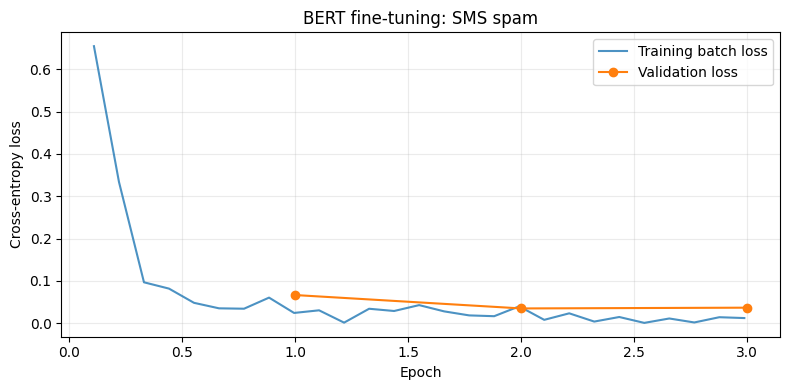

,epoch,eval_loss,eval_f1_spam,eval_accuracy
9,1.0,0.0665,0.9462,0.9871
19,2.0,0.0348,0.9645,0.9910
29,3.0,0.0366,0.9637,0.9910


Validation loss зростав між епохами: True
Найкращий checkpoint: checkpoint-452


In [7]:
train_logs = history.dropna(subset=['loss'])
val_logs = history.dropna(subset=['eval_loss'])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(train_logs.epoch, train_logs.loss, label='Training batch loss', alpha=0.8)
ax.plot(val_logs.epoch, val_logs.eval_loss, marker='o', label='Validation loss')
ax.set(xlabel='Epoch', ylabel='Cross-entropy loss', title='BERT fine-tuning: SMS spam')
ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS / 'loss.png', dpi=160)
plt.show()
display(val_logs[['epoch', 'eval_loss', 'eval_f1_spam', 'eval_accuracy']].round(4))
overfitting_seen = bool((val_logs.eval_loss.diff().dropna() > 0).any())
print('Validation loss зростав між епохами:', overfitting_seen)
print('Найкращий checkpoint:', training_info['best_checkpoint'])

## 1.5. Порівняння та аналіз помилок

Використовуємо незмінений test і ті самі 10 прикладів. Поріг рішення фіксований:
обираємо клас із більшим logit, тобто spam при `P(spam) > 0.5` (при рівності — ham).
Тестові результати не використовуємо для повторного підбору параметрів.
Окремі власні повідомлення нижче — демонстрація, вони не входять у метрики датасету.

,accuracy,precision_spam,recall_spam,f1_spam,macro_f1
method,,,,,
Majority baseline,0.8760,0.0000,0.0000,0.0000,0.4669
BERT before,0.2261,0.1274,0.8958,0.2231,0.2261
TF-IDF + LR,0.9625,1.0000,0.6979,0.8221,0.9006
BERT after,0.9961,0.9697,1.0000,0.9846,0.9912


,source_id,text,label_name,majority,BERT_before,BERT_after
736,1496,Hey gals.. Anyone of u going down to e driving centre tmr?,ham,ham,spam,ham
379,5320,"Good morning, my Love ... I go to sleep now and wish you a great day full of feeling better and opportunity ... You are my last thought babe, I LOVE YOU *kiss*",ham,ham,spam,ham
68,3941,Does daddy have a bb now.,ham,ham,spam,ham
412,1840,Are we doing the norm tomorrow? I finish just a 4.15 cos of st tests. Need to sort library stuff out at some point tomo - got letter from today - access til end march so i bett...,ham,ham,spam,ham
108,2391,First has she gained more than &lt;#&gt; kg since she took in. Second has she done the blood sugar tests. If she has and its ok and her blood pressure is within normal limits ...,ham,ham,ham,ham
684,3222,"Thanks for your ringtone order, reference number X29. Your mobile will be charged 4.50. Should your tone not arrive please call customer services 09065989180",spam,ham,spam,spam
671,4752,Your weekly Cool-Mob tones are ready to download !This weeks new Tones include: 1) Crazy Frog-AXEL F>>> 2) Akon-Lonely>>> 3) Black Eyed-Dont P >>>More info in n,spam,ham,spam,spam
658,160,You are a winner U have been specially selected 2 receive £1000 cash or a 4* holiday (flights inc) speak to a live operator 2 claim 0871277810810,spam,ham,ham,spam
757,4256,Block Breaker now comes in deluxe format with new features and great graphics from T-Mobile. Buy for just £5 by replying GET BBDELUXE and take the challenge,spam,ham,spam,spam
288,1993,Free tones Hope you enjoyed your new content. text stop to 61610 to unsubscribe. help:08712400602450p Provided by tones2you.co.uk,spam,ham,spam,spam


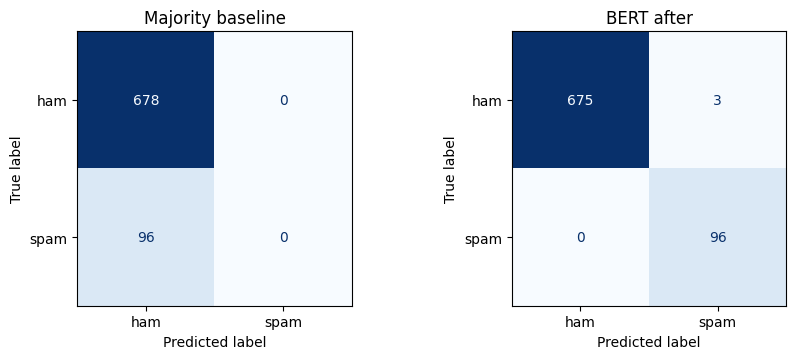

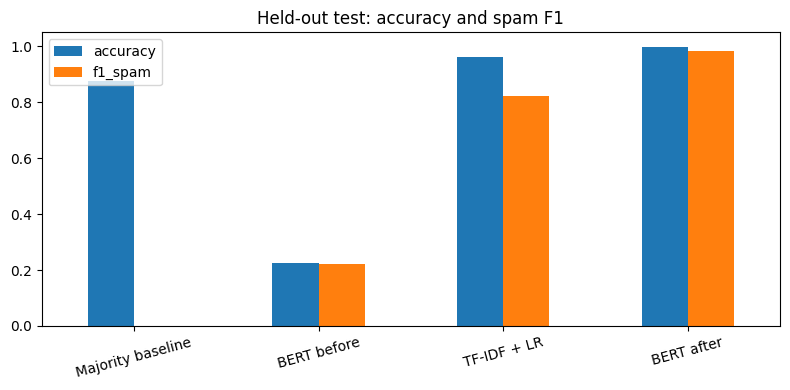

              precision    recall  f1-score   support

         ham     1.0000    0.9956    0.9978       678
        spam     0.9697    1.0000    0.9846        96

    accuracy                         0.9961       774
   macro avg     0.9848    0.9978    0.9912       774
weighted avg     0.9962    0.9961    0.9961       774

Помилки:


,source_id,text,label_name,majority,BERT_before,TFIDF_LR,BERT_after,prob_spam_after,error_type,wrong_confidence
683,1506,Total video converter free download type this in google search:),ham,0,1,0,1,0.997617,false positive,0.997617
25,4225,Double eviction this week - Spiral and Michael and good riddance to them!,ham,0,0,0,1,0.975878,false positive,0.975878
199,4210,I want kfc its Tuesday. Only buy 2 meals ONLY 2. No gravy. Only 2 Mark. 2!,ham,0,1,0,1,0.801781,false positive,0.801781


Пропущено спаму (FN): 0; звичайних SMS помилково позначено як спам (FP): 3.


In [8]:
after_pred, after_prob = predict_texts(test_df.text.tolist())
scores['BERT after'] = metrics(y_test, after_pred)
comparison = pd.DataFrame(scores).T
comparison.index.name = 'method'
display(comparison.round(4))
comparison.to_csv(RESULTS / 'metrics.csv')
examples['BERT_after'] = np.where(after_pred[example_indices] == 1, 'spam', 'ham')
display(examples)
examples.to_csv(RESULTS / 'same_10_examples.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
for ax, pred, title in zip(axes, [majority_pred, after_pred], ['Majority baseline', 'BERT after']):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]),
                           display_labels=['ham', 'spam']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title)
fig.tight_layout(); fig.savefig(RESULTS / 'confusion_matrix.png', dpi=160)
plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
comparison[['accuracy', 'f1_spam']].plot.bar(ax=ax, rot=15, ylim=(0, 1.05))
ax.set_title('Held-out test: accuracy and spam F1'); ax.set_xlabel('')
fig.tight_layout(); fig.savefig(RESULTS / 'comparison.png', dpi=160)
plt.show()
print(classification_report(y_test, after_pred, target_names=['ham', 'spam'], digits=4, zero_division=0))

predictions = test_df[['source_id', 'text', 'label_name']].copy()
predictions['majority'] = majority_pred
predictions['BERT_before'] = before_pred
predictions['TFIDF_LR'] = tfidf_pred
predictions['BERT_after'] = after_pred
predictions['prob_spam_after'] = after_prob
predictions.to_csv(RESULTS / 'test_predictions.csv', index=False)
errors = predictions.loc[after_pred != y_test].copy()
errors['error_type'] = np.where(errors.BERT_after == 1, 'false positive', 'false negative')
errors['wrong_confidence'] = np.maximum(errors.prob_spam_after, 1-errors.prob_spam_after)
errors = errors.sort_values('wrong_confidence', ascending=False)
errors.to_csv(RESULTS / 'errors.csv', index=False)
print('Помилки:'); display(errors.head(10))
tn, fp, fn, tp = confusion_matrix(y_test, after_pred, labels=[0, 1]).ravel()
print(f'Пропущено спаму (FN): {fn}; звичайних SMS помилково позначено як спам (FP): {fp}.')

In [9]:
# Ці приклади написані окремо, у навчальні дані не додаються.
custom = pd.DataFrame([
    ('Congratulations! You won a cash prize. Call this number now to claim it.', 'spam'),
    ('URGENT! Claim your free reward by texting WIN to 80001.', 'spam'),
    ('Exclusive offer! Get a free holiday voucher. Reply YES now.', 'spam'),
    ('Your number was selected for a prize. Call our premium line today.', 'spam'),
    ('Win cash today! Text LUCKY to 80002. Subscription charges apply.', 'spam'),
    ('Can you pick me up at the station at six?', 'ham'),
    ('Please call me when you get home.', 'ham'),
    ('Happy birthday! Hope you have a wonderful day.', 'ham'),
    ('Are you free for lunch tomorrow?', 'ham'),
    ('I won the game! See you after class.', 'ham')], columns=['text', 'expected'])
custom_pred, custom_prob = predict_texts(custom.text.tolist())
custom['predicted'] = np.where(custom_pred == 1, 'spam', 'ham')
custom['prob_spam'] = custom_prob
custom['correct'] = custom.expected == custom.predicted
display(custom)
custom.to_csv(RESULTS / 'custom_examples.csv', index=False)

# Перевірка чутливості до мінімальних змін; це діагностика, не новий тестовий набір.
probes = pd.DataFrame({'text': [
    'Are you free tonight?',
    'Free prize! Text WIN now to claim your reward.',
    'I won a prize at school today.',
    'You won a prize! Call 09001234567 to claim now.'
]})
probe_pred, probe_prob = predict_texts(probes.text.tolist())
probes['predicted'] = np.where(probe_pred == 1, 'spam', 'ham')
probes['prob_spam'] = probe_prob
display(probes)
probes.to_csv(RESULTS / 'diagnostic_examples.csv', index=False)

,text,expected,predicted,prob_spam,correct
0,Congratulations! You won a cash prize. Call this number now to claim it.,spam,spam,0.958886,True
1,URGENT! Claim your free reward by texting WIN to 80001.,spam,spam,0.999499,True
2,Exclusive offer! Get a free holiday voucher. Reply YES now.,spam,spam,0.999073,True
3,Your number was selected for a prize. Call our premium line today.,spam,spam,0.976220,True
4,Win cash today! Text LUCKY to 80002. Subscription charges apply.,spam,spam,0.999540,True
5,Can you pick me up at the station at six?,ham,ham,0.004574,True
6,Please call me when you get home.,ham,ham,0.001466,True
7,Happy birthday! Hope you have a wonderful day.,ham,ham,0.001617,True
8,Are you free for lunch tomorrow?,ham,ham,0.032868,True
9,I won the game! See you after class.,ham,ham,0.003004,True


,text,predicted,prob_spam
0,Are you free tonight?,ham,0.016482
1,Free prize! Text WIN now to claim your reward.,spam,0.998920
2,I won a prize at school today.,ham,0.002683
3,You won a prize! Call 09001234567 to claim now.,spam,0.999147


### Як трактувати помилки

`False positive` означає, що звичайне повідомлення потрапило до спаму — користувач
може пропустити важливу SMS. `False negative` означає пропущений спам. Таблиця вище
показує фактичні помилки, починаючи з найбільш упевнених неправильних відповідей.

За текстами можна перевірити припущення: чи є в хибно заблокованих SMS слова на
кшталт *free*, *win*, *call*, а в пропущеному спамі — незвичні формулювання або
слабко виражені рекламні ознаки. Наявність слова сама по собі не доводить причину
рішення нейромережі. Діагностичні приклади допомагають побачити, чи враховується
контекст, але не замінюють оцінювання на незалежному наборі.

Обмеження: старий англомовний корпус, дисбаланс класів, можливі подібні рекламні
шаблони в різних частинах даних. Якість на сучасному фішингу або українських SMS
цим експериментом не перевірялась. Для реального застосування потрібні нові дані
й окреме оцінювання вартості помилок. Невеликий набір не доводить переваги BERT
над усіма класичними методами; для цього й додано TF-IDF як орієнтир.

### Ручний розбір помилок локального запуску

У збереженому запуску модель зробила три помилки, усі — false positive:

1. **«Total video converter free download type this in google search:)»** — дружня порада, позначена авторами як ham. Фраза *free download* схожа на рекламний заклик; це можливе пояснення хибного спрацьовування.
2. **«Double eviction this week - Spiral and Michael and good riddance to them!»** — коментар про подію та людей, а не рекламна пропозиція. Тут немає очевидного заклику отримати приз або зателефонувати; помилка показує обмеження узагальнення на незвичний розмовний контекст.
3. **«I want kfc its Tuesday. Only buy 2 meals ONLY 2. No gravy. Only 2 Mark. 2!»** — особисте прохання купити їжу. Слова *buy*, *ONLY* і повторення цифр зовні нагадують рекламну акцію, але контекст побутовий.

Це інтерпретації текстів, а не доведені причинні пояснення рішень BERT. Серед помилок також є дуже впевнені прогнози: softmax-оцінка не гарантує правильність і не є перевіреною каліброваною ймовірністю. У цьому запуску пропущеного спаму немає, проте цей висновок стосується лише 96 спам-SMS тестового набору.

Після третьої епохи validation loss трохи зріс; для тесту автоматично повернуто модель після другої епохи. Гіперпараметри після перегляду тесту не змінювалися. При новому запуску слід звірити цей ручний розбір з актуальною таблицею помилок.


## 1.6. Мій звіт

Наступна клітинка формує звіт із фактичних результатів цього запуску.

In [10]:
def markdown_table(frame):
    # Без додаткової залежності tabulate; безпечне відображення SMS у таблицях.
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return f'{v:.4f}'
        return str(v).replace('|', r'\|').replace('\n', ' ')
    columns = [str(c) for c in frame.columns]
    lines = ['| ' + ' | '.join(columns) + ' |', '| ' + ' | '.join(['---']*len(columns)) + ' |']
    lines += ['| ' + ' | '.join(fmt(v) for v in row) + ' |'
              for row in frame.itertuples(index=False, name=None)]
    return '\n'.join(lines)

baseline_f1 = scores['Majority baseline']['f1_spam']
before_f1 = scores['BERT before']['f1_spam']
after_f1 = scores['BERT after']['f1_spam']
tfidf_f1 = scores['TF-IDF + LR']['f1_spam']
best_epoch = float(val_logs.loc[val_logs.eval_loss.idxmin(), 'epoch'])
if overfitting_seen:
    loss_comment = ('Validation loss зростав принаймні на одному переході між епохами. '
        'Це ознака можливого перенавчання. Застосовано заздалегідь заданий early stopping '
        'та повернуто checkpoint із найменшим validation loss; тест для цього не використовувався.')
else:
    loss_comment = ('Validation loss не зростав між оціненими епохами. За цією кривою '
        'явних ознак перенавчання в межах запуску не виявлено. '
        'Для фінальної оцінки повернуто checkpoint із найменшим validation loss.')
if after_f1 > tfidf_f1:
    baseline_comment = f'BERT перевищив TF-IDF + LR на {(after_f1-tfidf_f1)*100:.2f} відсоткового пункту F1.'
else:
    baseline_comment = ('TF-IDF + LR виявився не гіршим за BERT за F1 у цьому запуску. '
        'Отже, для такого малого корпусу простий метод також є практичним варіантом; '
        'доцільність BERT не можна обґрунтувати лише цим порівнянням.')
error_snippets = []
for row in errors.head(5).itertuples():
    predicted = 'spam' if row.BERT_after == 1 else 'ham'
    # Прямі текстові свідчення, без вигаданої впевненості щодо причин.
    error_snippets.append({'Текст': row.text, 'Правильно': row.label_name,
                           'Прогноз': predicted, 'Тип': row.error_type})
error_details = (markdown_table(pd.DataFrame(error_snippets)) if error_snippets
                 else 'На цьому тестовому наборі помилок не виявлено; це не гарантує їх відсутності на нових SMS.')

manual_notes = {
    1506: 'Порада про відеоконвертер містить free download, що нагадує рекламний заклик; це можливе пояснення false positive.',
    4225: 'Коментар про подію та людей не містить очевидного рекламного заклику. Хибне спрацьовування показує обмеження на незвичному розмовному контексті.',
    4210: 'Особисте прохання купити їжу містить buy, ONLY і повторення цифр, що зовні нагадує акцію; це можливе пояснення помилки.'}
selected_notes = [f'- source_id={int(row.source_id)}: {manual_notes[int(row.source_id)]}'
                  for row in errors.itertuples() if int(row.source_id) in manual_notes]
if selected_notes:
    error_details += '\n\nРучні спостереження за конкретними текстами цього корпусу:\n\n' + '\n'.join(selected_notes)

report = f"""# Звіт: донавчання BERT для визначення спаму в SMS

**Задача і чому потрібне донавчання.** Класифікація англомовних SMS на ham/spam
для фільтра повідомлень. Базовий BERT не має навченої голови для цих міток;
донавчання пристосовує його до задачі. Промпт не навчає класифікаційну голову,
а RAG не потрібен, бо зовнішні факти не використовуються.

**Модель і дані.** `google-bert/bert-base-uncased`, base, близько 110 млн параметрів,
Apache 2.0; ревізія `{MODEL_REVISION}`. SMS Spam Collection, UCI,
Ліцензія датасету — CC BY 4.0 за карткою UCI.
У завантаженому файлі {len(raw)} рядків, після очищення {len(clean)}.
Вилучено {len(raw)-len(clean)} рядків через дублікати або суперечливу розмітку.
Однакові токенізовані входи не перетинаються між частинами.

{markdown_table(split_summary)}

**Метрика й результат до донавчання.** Основна метрика — F1 для spam;
додаткові — accuracy, precision, recall та macro-F1.
F1 базового рівня «завжди найчастіший клас»: {baseline_f1:.4f}.
F1 BERT із ненавченою головою: {before_f1:.4f}. Його випадкові прогнози
не означають готової здатності базової моделі класифікувати спам.

**Метод донавчання й гіперпараметри.** Повне донавчання backbone і нової голови;
learning rate 2e-5, batch 16, до 3 епох, max_length 128, weight decay 0.01,
warmup 10%, лінійний scheduler, AdamW, fp16, seed 42.
Виконано {training_info['global_steps']} кроків, {training_info['completed_epochs']:.2f} епох.
Найкраща епоха за validation loss: {best_epoch:g}.
Час trainer.train(): {training_seconds:.1f} с ({training_seconds/60:.2f} хв).
GPU: {environment['gpu']}. Пік PyTorch CUDA allocated: {peak_allocated_gib:.2f} GiB,
reserved: {peak_reserved_gib:.2f} GiB. {loss_comment}

**Результат після донавчання.** Усі методи оцінено на тих самих {len(test_df)} SMS.

{markdown_table(comparison.reset_index())}

Зміна F1 BERT щодо ненавченої голови: {(after_f1-before_f1)*100:+.2f} в.п.;
щодо базового рівня: {(after_f1-baseline_f1)*100:+.2f} в.п.
{baseline_comment}

**Аналіз помилок.** Правильно відхилено звичайних SMS: {tn}; знайдено спаму: {tp};
помилково заблоковано звичайних SMS (FP): {fp}; пропущено спаму (FN): {fn}.
Ось конкретні помилки цього запуску:

{error_details}

Хибні спрацьовування варто перевіряти на рекламні слова у звичайному контексті,
а пропуски — на нетипові формулювання спаму. Це гіпотези для ручного аналізу,
а не доведені причини роботи моделі. Корпус старий, англомовний; подібні шаблони
можуть залишатися в різних частинах. Новий фішинг і українську мову не перевіряли.
Приклади власних SMS демонстраційні й не включені в метрики test.

**Висновок.** На відкладеному тесті донавчений BERT отримав F1={after_f1:.4f}
та accuracy={scores['BERT after']['accuracy']:.4f}.
Експеримент показує зміну якості після навчання на конкретній задачі.
Він не доводить універсальну перевагу BERT або готовність до використання без
нового незалежного оцінювання. Ваги моделі в репозиторій не додаються.

"""
display(Markdown(report))
(RESULTS / 'REPORT.md').write_text(report, encoding='utf-8')
summary = {'environment': environment, 'data': data_info, 'training': training_info,
           'test_metrics': scores, 'confusion_matrix': {'tn': int(tn), 'fp': int(fp),
               'fn': int(fn), 'tp': int(tp)}, 'overfitting_signal': overfitting_seen}
(RESULTS / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
(RESULTS / 'environment.txt').write_text('\n'.join(
    f'{p}=={version(p)}' for p in ['torch', 'transformers', 'accelerate', 'pandas',
        'numpy', 'scikit-learn', 'matplotlib', 'huggingface-hub', 'tokenizers']), encoding='utf-8')
print('Збережено:', ', '.join(sorted(p.name for p in RESULTS.iterdir())))

# Звіт: донавчання BERT для визначення спаму в SMS

**Задача і чому потрібне донавчання.** Класифікація англомовних SMS на ham/spam
для фільтра повідомлень. Базовий BERT не має навченої голови для цих міток;
донавчання пристосовує його до задачі. Промпт не навчає класифікаційну голову,
а RAG не потрібен, бо зовнішні факти не використовуються.

**Модель і дані.** `google-bert/bert-base-uncased`, base, близько 110 млн параметрів,
Apache 2.0; ревізія `86b5e0934494bd15c9632b12f734a8a67f723594`. SMS Spam Collection, UCI,
Ліцензія датасету — CC BY 4.0 за карткою UCI.
У завантаженому файлі 5574 рядків, після очищення 5159.
Вилучено 415 рядків через дублікати або суперечливу розмітку.
Однакові токенізовані входи не перетинаються між частинами.

| split | total | ham | spam |
| --- | --- | --- | --- |
| train | 3611 | 3162 | 449 |
| validation | 774 | 677 | 97 |
| test | 774 | 678 | 96 |

**Метрика й результат до донавчання.** Основна метрика — F1 для spam;
додаткові — accuracy, precision, recall та macro-F1.
F1 базового рівня «завжди найчастіший клас»: 0.0000.
F1 BERT із ненавченою головою: 0.2231. Його випадкові прогнози
не означають готової здатності базової моделі класифікувати спам.

**Метод донавчання й гіперпараметри.** Повне донавчання backbone і нової голови;
learning rate 2e-5, batch 16, до 3 епох, max_length 128, weight decay 0.01,
warmup 10%, лінійний scheduler, AdamW, fp16, seed 42.
Виконано 678 кроків, 3.00 епох.
Найкраща епоха за validation loss: 2.
Час trainer.train(): 44.2 с (0.74 хв).
GPU: NVIDIA GeForce RTX 5070. Пік PyTorch CUDA allocated: 2.25 GiB,
reserved: 2.54 GiB. Validation loss зростав принаймні на одному переході між епохами. Це ознака можливого перенавчання. Застосовано заздалегідь заданий early stopping та повернуто checkpoint із найменшим validation loss; тест для цього не використовувався.

**Результат після донавчання.** Усі методи оцінено на тих самих 774 SMS.

| method | accuracy | precision_spam | recall_spam | f1_spam | macro_f1 |
| --- | --- | --- | --- | --- | --- |
| Majority baseline | 0.8760 | 0.0000 | 0.0000 | 0.0000 | 0.4669 |
| BERT before | 0.2261 | 0.1274 | 0.8958 | 0.2231 | 0.2261 |
| TF-IDF + LR | 0.9625 | 1.0000 | 0.6979 | 0.8221 | 0.9006 |
| BERT after | 0.9961 | 0.9697 | 1.0000 | 0.9846 | 0.9912 |

Зміна F1 BERT щодо ненавченої голови: +76.15 в.п.;
щодо базового рівня: +98.46 в.п.
BERT перевищив TF-IDF + LR на 16.25 відсоткового пункту F1.

**Аналіз помилок.** Правильно відхилено звичайних SMS: 675; знайдено спаму: 96;
помилково заблоковано звичайних SMS (FP): 3; пропущено спаму (FN): 0.
Ось конкретні помилки цього запуску:

| Текст | Правильно | Прогноз | Тип |
| --- | --- | --- | --- |
| Total video converter free download type this in google search:) | ham | spam | false positive |
| Double eviction this week - Spiral and Michael and good riddance to them! | ham | spam | false positive |
| I want kfc its Tuesday. Only buy 2 meals ONLY 2. No gravy. Only 2 Mark. 2! | ham | spam | false positive |

Ручні спостереження за конкретними текстами цього корпусу:

- source_id=1506: Порада про відеоконвертер містить free download, що нагадує рекламний заклик; це можливе пояснення false positive.
- source_id=4225: Коментар про подію та людей не містить очевидного рекламного заклику. Хибне спрацьовування показує обмеження на незвичному розмовному контексті.
- source_id=4210: Особисте прохання купити їжу містить buy, ONLY і повторення цифр, що зовні нагадує акцію; це можливе пояснення помилки.

Хибні спрацьовування варто перевіряти на рекламні слова у звичайному контексті,
а пропуски — на нетипові формулювання спаму. Це гіпотези для ручного аналізу,
а не доведені причини роботи моделі. Корпус старий, англомовний; подібні шаблони
можуть залишатися в різних частинах. Новий фішинг і українську мову не перевіряли.
Приклади власних SMS демонстраційні й не включені в метрики test.

**Висновок.** На відкладеному тесті донавчений BERT отримав F1=0.9846
та accuracy=0.9961.
Експеримент показує зміну якості після навчання на конкретній задачі.
Він не доводить універсальну перевагу BERT або готовність до використання без
нового незалежного оцінювання. Ваги моделі в репозиторій не додаються.



Збережено: REPORT.md, comparison.png, confusion_matrix.png, custom_examples.csv, diagnostic_examples.csv, environment.txt, errors.csv, loss.png, metrics.csv, model_revision.txt, same_10_examples.csv, split_manifest.csv, split_summary.csv, summary.json, test_predictions.csv, training_history.csv
